# IoTShield — 01: Keşifsel Veri Analizi (EDA) ve Veri Ön İşleme
**SE3513 · ASEADOS-SDN-IoT · 5 sınıf (Benign, Dos, DDoS, Bot, Prob)**

Bu notebook veriyi tanır, temizleme kurallarını (`src/preprocessing.clean()`) ve değerlendirme yöntemini (`src/cv.get_folds()`) gerekçelendirir.
Her bölüm üç parçadan oluşur: *ne yapıyoruz → kod → ne bulduk / ne karar verdik*.

**Bulgu → karar özeti** (sayılar aşağıdaki bölümlerde ölçüldü):

| # | Bulgu | Karar | Bölüm |
|---|---|---|---|
| 1 | `Protocol == 0` olan 127.290 satır (%27,9) bozuk: bayt, başlık, flag ve port alanları 0 / −1. Bot, DDoS ve Prob'un tamamı; Benign'in 42.740, Dos'un 16.075 satırı. | Her deney üç skorla raporlanır: tüm veri, sağlam alt küme (Benign/Dos), bozuk alt küme. | 4 |
| 2 | Zero-byte (`Flow Byts/s == 0`) 225.254 satır; bozuk satırların neredeyse hepsi zero-byte, ama zero-byte satırların %44'ü (98.029) sağlam. | "Zero-byte" ve "bozuk" ayrı tanımlar; zero-byte tek başına bozukluk göstergesi değil. | 4.1 |
| 3 | Saldırılar birkaç kısa oturumda kaydedilmiş: Bot 6 aktif dakika / 3 oturum, DDoS 11 / 4. | Oturum gruplu 3 katlı CV (`get_folds`); ayrı test seti yok; sonuç ortalama ± std. | 5.0 |
| 4 | Aynı satırlarda rastgele CV, macro F1'i gruplu CV'den 0,15–0,21 yüksek gösteriyor. | Rastgele bölme sadece bu karşılaştırma için kullanılır. | 9 |
| 5 | Dos iki kayıt döneminden geliyor (2023: %99,96 sağlam; 2025); süre, hız ve pencere dağılımları farklı. Gruplu CV'de Dos sonuçları kata göre çok değişiyor. | Sınırlılık olarak raporlanır; `get_folds` değiştirilmez. | 5.1, 9 |
| 6 | Bozuk + 1/1 paketli satırlarda F_timing vektörü tamamen süreden belirleniyor (95.994 satır; Bot'un %92'si, DDoS'un %86'sı). Bot'un %84'ü DDoS tahmin ediliyor. | Bot/DDoS örtüşmesi ayrıca incelenir (WP-D2). | 8.2, 9 |
| 7 | Sadece F_timing ile `broken` bayrağı OOF AUC 0,998 ile tahmin ediliyor. | Byte kısayolu kalktı, bozuk-oturum bilgisi zamanlamada duruyor: sınırlılık olarak raporlanır. | 8.4 |
| 8 | Gruplu CV'de F_full 0,499 ± 0,052, F_timing 0,418 ± 0,119; fark çoğunlukla sağlam alt kümede. | Ana deney seti F_timing (deney tutarlılığı, Mininet'e taşınabilirlik), F_full karşılaştırma seti. | 9 |
| 9 | Dengesizlik 30,9 : 1; IQR kuralı sınıfa göre satırların %22–%90'ını outlier sayıyor. | Ana metrik macro F1 + sınıf recall; outlier satırlar silinmiyor. | 2, 8.1 |
| 10 | Aynı özellik vektörü farklı etiket taşıyan satırlar var (ham veride ~3,7 bin). | `clean()` bunları silmez; sadece eğitim katından atılır (`run_cv`). | 3 |

In [1]:
import sys
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns

# WP-D1 7.1: paths, constants and column lists come from src/ (single source for notebook + app)
sys.path.append('..')
from src.config import (DATA_PATH, RANDOM_STATE, CONSTANT_COLS, DUPLICATE_COLS, FEATS,
                        ARTIFACT_COLS, TIMING_COLS, F_TIMING, F_FULL)
from src.preprocessing import clean, add_eval_columns
from src.cv import make_groups, get_folds

pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')
CLASS_ORDER = ['Benign', 'Dos', 'DDoS', 'Bot', 'Prob']
FIG_DIR = '../reports/figures/'

## 1. Veriyi yükleme ve ilk bakış

In [2]:
df = pd.read_csv(DATA_PATH, low_memory=False)
df.columns = df.columns.str.strip()
print(df.shape)
df.info(verbose=False)
df.head()

(457044, 84)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 457044 entries, 0 to 457043
Columns: 84 entries, Flow ID to Label
dtypes: float64(45), int64(34), object(5)
memory usage: 292.9+ MB


,Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,Fwd Pkt Len Mean,Fwd Pkt Len Std,Bwd Pkt Len Max,Bwd Pkt Len Min,Bwd Pkt Len Mean,Bwd Pkt Len Std,Flow Byts/s,Flow Pkts/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Tot,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Tot,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Len,Bwd Header Len,Fwd Pkts/s,Bwd Pkts/s,Pkt Len Min,Pkt Len Max,Pkt Len Mean,Pkt Len Std,Pkt Len Var,FIN Flag Cnt,SYN Flag Cnt,RST Flag Cnt,PSH Flag Cnt,ACK Flag Cnt,URG Flag Cnt,CWE Flag Count,ECE Flag Cnt,Down/Up Ratio,Pkt Size Avg,Fwd Seg Size Avg,Bwd Seg Size Avg,Fwd Byts/b Avg,Fwd Pkts/b Avg,Fwd Blk Rate Avg,Bwd Byts/b Avg,Bwd Pkts/b Avg,Bwd Blk Rate Avg,Subflow Fwd Pkts,Subflow Fwd Byts,Subflow Bwd Pkts,Subflow Bwd Byts,Init Fwd Win Byts,Init Bwd Win Byts,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,8.128.192.168-85.245.192.168-0-0-0,85.245.192.168,0,8.128.192.168,0,0,12/03/2025 03:07:04 PM,3241760,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.616949,3241760.0,0.0,3241760.0,3241760.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0.308474,0.308474,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,1,0,1,0,-1,-1,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Bot
1,8.128.192.168-31.125.192.168-0-0-0,31.125.192.168,0,8.128.192.168,0,0,12/03/2025 03:07:08 PM,17649667,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.113317,17649667.0,0.0,17649667.0,17649667.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0.056658,0.056658,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,1,0,1,0,-1,-1,0,0,0.0,0.0,0.0,0.0,17649667.0,0.0,17649667.0,17649667.0,Bot
2,8.128.192.168-82.28.192.168-0-0-0,82.28.192.168,0,8.128.192.168,0,0,12/03/2025 03:07:07 PM,24923670,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.080245,24923670.0,0.0,24923670.0,24923670.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0.040123,0.040123,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,1,0,1,0,-1,-1,0,0,0.0,0.0,0.0,0.0,24923670.0,0.0,24923670.0,24923670.0,Bot
3,8.128.192.168-76.22.192.168-0-0-0,76.22.192.168,0,8.128.192.168,0,0,12/03/2025 03:07:27 PM,5399930,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.370375,5399930.0,0.0,5399930.0,5399930.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0.185188,0.185188,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,1,0,1,0,-1,-1,0,0,0.0,0.0,0.0,0.0,5399930.0,0.0,5399930.0,5399930.0,Bot
4,8.128.192.168-72.128.192.168-0-0-0,72.128.192.168,0,8.128.192.168,0,0,12/03/2025 03:07:27 PM,5436008,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.367917,5436008.0,0.0,5436008.0,5436008.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0.183959,0.183959,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,1,0,1,0,-1,-1,0,0,0.0,0.0,0.0,0.0,5436008.0,0.0,5436008.0,5436008.0,Bot


## 2. Sınıf dağılımı
Dengesizliği görmek ve metrik seçimimizi (macro F1) gerekçelendirmek için.

,adet,oran_%
Label,,
Benign,260797,57.06
Dos,127772,27.96
DDoS,51465,11.26
Bot,9090,1.99
Prob,7920,1.73


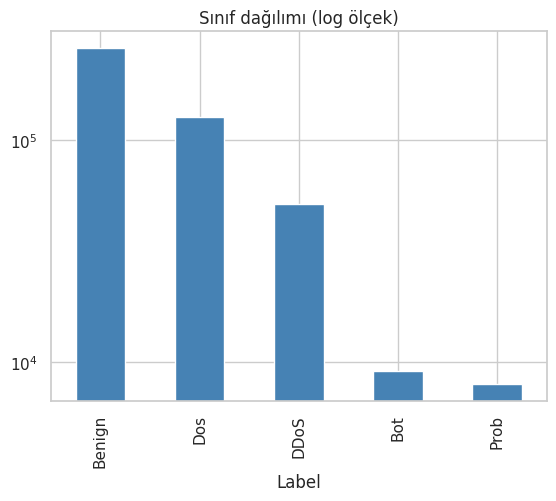

In [3]:
vc = df['Label'].value_counts().reindex(CLASS_ORDER)
display(pd.DataFrame({'adet': vc, 'oran_%': (vc / len(df) * 100).round(2)}))
ax = vc.plot.bar(color='steelblue'); ax.set_yscale('log'); ax.set_title('Sınıf dağılımı (log ölçek)')
plt.savefig(FIG_DIR + 'eda_class_distribution.png', dpi=150, bbox_inches='tight'); plt.show()

**Bulgu:** Benign %57, Bot ve Prob ~%2. Accuracy yanıltıcı olur. Ana metrik **macro F1**, ayrıca sınıf bazında recall ve confusion matrix raporlanacak.

## 3. Veri kalitesi kontrolleri
Eksik / sonsuz / negatif değerler, sabit sütunlar, birebir aynı sütunlar, tekrar eden satırlar ve **aynı özellik değerleriyle farklı etiket taşıyan satırlar**.

In [4]:
ID_COLS   = ['Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'Dst Port', 'Protocol', 'Timestamp']
num_cols  = [c for c in df.columns if c not in ID_COLS + ['Label']]
X = df[num_cols]

print('NaN    :', X.isna().sum()[lambda s: s > 0].to_dict())
print('inf    :', np.isinf(X).sum()[lambda s: s > 0].to_dict())
print('negatif:', (X < 0).sum()[lambda s: s > 0].to_dict())

const_cols = [c for c in num_cols if X[c].nunique(dropna=False) <= 1]
print(f'\nSabit sütun ({len(const_cols)}):', const_cols)

# Birebir aynı içerikli sütunlar
seen, dup_cols = {}, []
for c in num_cols:
    h = pd.util.hash_pandas_object(X[c], index=False).sum()
    (dup_cols.append((c, seen[h])) if h in seen else seen.__setitem__(h, c))
dup_pairs = [p for p in dup_cols if p[0] not in const_cols]
print('\nBirebir aynı sütunlar:', dup_pairs)

# 7.1: the lists used in code come from src/config.py; here we only check they match what we see.
assert const_cols == CONSTANT_COLS
assert sorted(p[0] for p in dup_pairs) == sorted(DUPLICATE_COLS)

NaN    : {'Flow Byts/s': 66}
inf    : {'Flow Byts/s': 4, 'Flow Pkts/s': 70}
negatif: {'Flow Duration': 2, 'Flow Pkts/s': 2, 'Flow IAT Mean': 2, 'Flow IAT Max': 1, 'Flow IAT Min': 427, 'Fwd IAT Min': 10, 'Bwd IAT Tot': 1, 'Bwd IAT Mean': 1, 'Bwd IAT Max': 1, 'Bwd IAT Min': 11, 'Init Fwd Win Byts': 457044, 'Init Bwd Win Byts': 128878}



Sabit sütun (14): ['Fwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'URG Flag Cnt', 'CWE Flag Count', 'ECE Flag Cnt', 'Fwd Byts/b Avg', 'Fwd Pkts/b Avg', 'Fwd Blk Rate Avg', 'Bwd Byts/b Avg', 'Bwd Pkts/b Avg', 'Bwd Blk Rate Avg', 'Init Fwd Win Byts', 'Fwd Seg Size Min']

Birebir aynı sütunlar: [('PSH Flag Cnt', 'Bwd PSH Flags'), ('Subflow Fwd Pkts', 'Tot Fwd Pkts'), ('Subflow Bwd Pkts', 'Tot Bwd Pkts')]


In [5]:
dup_mask = df.duplicated(subset=num_cols + ['Label'])
print('Tekrar eden satır (özellik+etiket):', dup_mask.sum())
display(df.loc[dup_mask, 'Label'].value_counts())

n_labels = df.groupby(num_cols, dropna=False)['Label'].transform('nunique')
print('Aynı özellik vektörü, farklı etiket (çelişkili) satır:', (n_labels > 1).sum())
display(df.loc[n_labels > 1, 'Label'].value_counts())

Tekrar eden satır (özellik+etiket): 29993


Label
Benign    27046
Dos        1265
DDoS       1195
Prob        354
Bot         133
Name: count, dtype: int64

Aynı özellik vektörü, farklı etiket (çelişkili) satır: 3763


Label
DDoS      1310
Dos        965
Benign     640
Prob       493
Bot        355
Name: count, dtype: int64

**Bulgu:**
- `Flow Byts/s` (66 NaN, 4 inf) ve `Flow Pkts/s` (70 inf): bu 70 satırın hepsinde süre 0, yani hız sonsuz. Bu satırlar **atılıyor** (`clean()` adım 3); 0 ile doldurmak "hiç paket yok" anlamına gelirdi.
- Birkaç yüz satırda negatif IAT/süre var (saat kayması olabilir; doğrulanmadı). **0'a kırpılıyor.** `Init Bwd Win Byts` kırpılmıyor: −1 "bilgi yok" anlamında.
- 14 sabit sütun var (`Init Fwd Win Byts` hep −1, bulk/URG/CWE/ECE sütunları hep 0). **Atılıyor.**
- `Subflow Fwd/Bwd Pkts` sütunları `Tot Fwd/Bwd Pkts` ile, `PSH Flag Cnt` de `Bwd PSH Flags` ile birebir aynı. **Kopyalar atılıyor** (`DUPLICATE_COLS`).
- ~30 bin tekrar eden satır var (çoğu Benign). **`clean()` içinde siliniyor**; yoksa aynı satır hem eğitim hem test katına düşebilir.
- 709 özellik vektörü birden fazla etiket taşıyor (~3.7 bin satır): aynı özellik vektörü farklı etiket taşıyor; bu satırlarda doğruluğun bir üst sınırı var. **Çelişkili satırlar `clean()` içinde silinmiyor**; sadece eğitim katından atılıyor (`run_cv`), test katında kalıyor.

## 4. ⭐ Asıl sorunun analizi: "byte = 0" kimde, neden?
Danışma raporundaki hipotez "Bot/DDoS/Prob'da byte bilgisi okunamamış" idi. Bunu sınıf bazında değil, **`Protocol == 0` (bozuk ayrıştırma) bayrağı** üzerinden inceliyoruz.

In [6]:
BYTE_COLS = ['TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Flow Byts/s', 'Pkt Len Max']
df['broken'] = df['Protocol'] == 0
df['bytes0'] = (df[BYTE_COLS] == 0).all(axis=1)

display(pd.crosstab(df['Label'], df['Protocol']).reindex(CLASS_ORDER))
display(pd.crosstab(df['Label'], df['broken'], margins=True).reindex(CLASS_ORDER + ['All']))
print('Bozuk satırlarda byte=0 oranı:', df.loc[df.broken, 'bytes0'].mean().round(3))

Protocol,0,6,17
Label,,,
Benign,42740,216512,1545
Dos,16075,111654,43
DDoS,51465,0,0
Bot,9090,0,0
Prob,7920,0,0


broken,False,True,All
Label,,,
Benign,218057,42740,260797
Dos,111697,16075,127772
DDoS,0,51465,51465
Bot,0,9090,9090
Prob,0,7920,7920
All,329754,127290,457044


Bozuk satırlarda byte=0 oranı: 0.999


### 4.1 "Bayt" ne demek? Bayt sütunları × sınıf ve zero-byte tanımı
CICFlowMeter'da `TotLen Fwd/Bwd Pkts` ve `Pkt Len *` sütunları paket **yükünü (payload)** bayt olarak sayar; başlık baytları `Fwd/Bwd Header Len` sütunlarındadır.
Raporda **zero-byte** dediğimizde tek bir tanım kullanıyoruz: **`Flow Byts/s == 0`** (akış boyunca hiç yük baytı görülmemiş).
Tablo: her sınıf ve sağlam/bozuk satırlar için, bayt ile ilgili sütunların yüzde kaçı ≤ 0.

In [7]:
# 7.9: byte-related columns; <= 0 because Init Bwd Win Byts uses -1 for "no information"
BYTE_TABLE_COLS = ['TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Flow Byts/s', 'Pkt Len Max',
                   'Fwd Header Len', 'Init Bwd Win Byts']
is_zero = df[BYTE_TABLE_COLS] <= 0
byte_zero_pct = is_zero.groupby([df['Label'], df['broken']]).mean() * 100
display(byte_zero_pct.reindex(CLASS_ORDER, level=0).round(1))

# zero-byte definition used in the report
df['zero_byte'] = df['Flow Byts/s'] == 0
display(pd.crosstab([df['Label'], df['broken']], df['zero_byte'], margins=True))

TotLen Fwd Pkts  TotLen Bwd Pkts  Flow Byts/s  Pkt Len Max  \
Label  broken                                                               
Benign False              45.8             48.9         39.1         39.1   
       True              100.0            100.0        100.0        100.0   
Dos    False              34.7             17.9         11.4         11.4   
       True              100.0            100.0        100.0        100.0   
DDoS   True              100.0            100.0        100.0        100.0   
Bot    True              100.0            100.0        100.0        100.0   
Prob   True              100.0            100.0         99.6        100.0   

               Fwd Header Len  Init Bwd Win Byts  
Label  broken                                     
Benign False             12.5               12.8  
       True             100.0              100.0  
Dos    False              3.2               24.5  
       True             100.0              100.0  
DDoS   True             100.0              100.0  
Bot    True             100.0              100.0  
Prob   True             100.0              100.0

zero_byte       False    True     All
Label  broken                        
Benign False   132817   85240  218057
       True        16   42724   42740
Bot    True         0    9090    9090
DDoS   True         8   51457   51465
Dos    False    98908   12789  111697
       True         6   16069   16075
Prob   True        35    7885    7920
All            231790  225254  457044

**Bulgu (7.9):**
- Bozuk satırlarda (`broken = True`) bu altı sütun 5 sınıfın hepsinde %99,6–%100 oranında ≤ 0.
- Sağlam satırlarda da zero-byte akış var: Benign 85.240, Dos 12.789 satır (toplam 98.029). Zero-byte satırların (225.254) yaklaşık %44'ü sağlam. Yani **zero-byte ≠ bozuk**. Bu sağlam satırların neden yük taşımadığını (ör. sadece kontrol paketleri) ayrıca kontrol etmedik.
- Bu yüzden raporda "bayt" = yük (payload) baytı, "zero-byte" = `Flow Byts/s == 0`, "bozuk" = `Protocol == 0` olarak ayrı ayrı kullanılır.

In [8]:
# Bozuk satırlarda hangi özellikler hep 0 / -1? Bunlar "bozuk mu?" bilgisini sızdıran artefakt sütunları.
num_ok = [c for c in num_cols if c not in const_cols]
art = pd.DataFrame({
    'bozuk_satırda_<=0_%':  (df.loc[df.broken, num_ok] <= 0).mean() * 100,
    'normal_satırda_<=0_%': (df.loc[~df.broken, num_ok] <= 0).mean() * 100}).round(1)
art_found    = art.index[art['bozuk_satırda_<=0_%'] >= 99].tolist()   # %99+: Flow Byts/s gibi neredeyse hep 0 olanlar da dahil
timing_found = [c for c in num_ok if c not in art_found]
print(f'Bozuk satırlarda hep 0 olan ({len(art_found)}):', art_found)
print(f'\nBozuk satırlarda da değişen ({len(timing_found)}):', timing_found)

# 7.1: ARTIFACT_COLS (35) / TIMING_COLS (24) in src/config.py = these lists minus the 3 duplicate
# columns that clean() drops. The code below uses the config lists, not the ones computed here.
assert ARTIFACT_COLS == [c for c in art_found if c not in DUPLICATE_COLS]
assert TIMING_COLS == [c for c in timing_found if c not in DUPLICATE_COLS]
print(f'\nconfig: ARTIFACT_COLS {len(ARTIFACT_COLS)}, TIMING_COLS {len(TIMING_COLS)} (tekrar sütunları hariç)')

Bozuk satırlarda hep 0 olan (36): ['TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Fwd Pkt Len Max', 'Fwd Pkt Len Min', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Std', 'Bwd Pkt Len Max', 'Bwd Pkt Len Min', 'Bwd Pkt Len Mean', 'Bwd Pkt Len Std', 'Flow Byts/s', 'Bwd IAT Tot', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Bwd PSH Flags', 'Fwd Header Len', 'Bwd Header Len', 'Pkt Len Min', 'Pkt Len Max', 'Pkt Len Mean', 'Pkt Len Std', 'Pkt Len Var', 'FIN Flag Cnt', 'SYN Flag Cnt', 'RST Flag Cnt', 'PSH Flag Cnt', 'ACK Flag Cnt', 'Pkt Size Avg', 'Fwd Seg Size Avg', 'Bwd Seg Size Avg', 'Subflow Fwd Byts', 'Subflow Bwd Byts', 'Init Bwd Win Byts', 'Fwd Act Data Pkts']

Bozuk satırlarda da değişen (26): ['Flow Duration', 'Tot Fwd Pkts', 'Tot Bwd Pkts', 'Flow Pkts/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Tot', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Fwd Pkts/s', 'Bwd Pkts/s', 'Down/Up Ratio', 'Subflow Fwd Pkts', 'Subflow Bwd Pkts', 'Active M

In [9]:
# Bozuk satırlarda IP adresleri: 16-bit kelimeleri yer değiştirmiş görünüyor (8.128.192.168 -> 192.168.8.128)
swapped = df['Dst IP'].astype(str).str.match(r'^\d+\.\d+\.192\.168$')
display(pd.crosstab(df['Label'], swapped).reindex(CLASS_ORDER))
for lab in CLASS_ORDER:
    s = df[df.Label == lab]
    print(f"{lab:7s} benzersiz src={s['Src IP'].nunique():6d} dst={s['Dst IP'].nunique():6d} | en sık src: {s['Src IP'].value_counts().head(3).to_dict()}")

Dst IP,False,True
Label,,
Benign,246067,14730
Dos,111809,15963
DDoS,6831,44634
Bot,2,9088
Prob,7920,0


Benign  benzersiz src= 14306 dst= 11842 | en sık src: {'192.168.4.9': 44555, '192.168.40.152': 20833, '192.168.40.153': 20737}


Dos     benzersiz src= 14349 dst=    13 | en sık src: {'200.175.2.130': 108267, '192.168.4.17': 3193, '192.168.40.150': 137}
DDoS    benzersiz src= 32952 dst=  6673 | en sık src: {'44.207.103.122': 2759, '220.166.50.247': 1481, '184.39.235.66': 1462}
Bot     benzersiz src=  8651 dst=     3 | en sık src: {'111.6.192.168': 3, '205.219.192.168': 3, '24.201.192.168': 3}
Prob    benzersiz src=     8 dst=  5623 | en sık src: {'0.12.41.142': 3996, '0.12.41.223': 3436, '184.39.235.66': 226}


**Bulgu (en önemli kısım):**
- `Protocol == 0` olan **127.290 satırın 42.740'ı Benign, 16.075'i Dos.** Yani bozukluk Bot/DDoS/Prob'a özgü değil. Bunun **bazı kayıt oturumlarının CICFlowMeter tarafından yanlış ayrıştırılmasından** kaynaklandığını düşünüyoruz (hipotez; PCAP'ler elimizde değil).
- Bu satırlarda protokol, port, byte, header uzunluğu, flag ve TCP pencere bilgisi **hep 0 / −1**. Ellerinde yalnızca **zamanlama ve paket sayısı** kalıyor (`TIMING_COLS`, 24 sütun).
- IP adresleri de anlamsız görünüyor: `8.128.192.168`, `192.168.8.128` adresinin 16-bit yarıları yer değiştirmiş hâline benziyor. Prob'da kaynak IP'ler `0.12.41.142` gibi anlamsız. Bot'ta 9.090 akış 8.651 farklı "kaynaktan" geliyor gibi görünüyor, bu da gürültü.
  Hipotezimiz: **başlık alanları kaymış okunuyor** (örneğin Linux "cooked capture" (SLL, 16 byte) kaydının Ethernet (14 byte) gibi okunması). Bu bir **hipotez**; PCAP'e bakarak doğrulanabilir.
- **Sonuç 1:** IP'lerle "bu hedefe kaç kaynak bağlandı" gibi bağlantılar arası özellik üretmek (danışma raporundaki B seçeneği) bu satırlarda **güvenilir değil**, çünkü IP alanı bozuk.
- **Sonuç 2:** Model "bayt sütunları 0 → Bot/DDoS/Prob" kuralını öğrenirse, baytların dolu ölçüldüğü bir ortamda (ör. Mininet) bu kural geçersiz kalır. Bu yüzden ana deney seti F_timing bayt / başlık / flag sütunlarını içermiyor. Ama bozuk-oturum bilgisi zamanlama sütunlarında da duruyor (8.4).

## 5. ⭐ Zaman analizi: her saldırı ne zaman kaydedilmiş?
Bölme stratejisini belirleyen bölüm.

In [10]:
df['ts'] = pd.to_datetime(df['Timestamp'], format='%d/%m/%Y %I:%M:%S %p')
g = df.groupby('Label')['ts'].agg(['min', 'max', 'count']).reindex(CLASS_ORDER)
g['süre'] = g['max'] - g['min']; display(g)
display(pd.crosstab(df['ts'].dt.date, df['Label'])[CLASS_ORDER])

,min,max,count,süre
Label,,,,
Benign,2025-03-10 21:24:07,2025-03-24 12:23:14,260797,13 days 14:59:07
Dos,2023-11-22 02:24:11,2025-03-24 16:34:07,127772,488 days 14:09:56
DDoS,2025-03-10 15:47:43,2025-03-10 16:06:20,51465,0 days 00:18:37
Bot,2025-03-12 14:38:51,2025-03-12 15:11:08,9090,0 days 00:32:17
Prob,2025-02-10 16:45:56,2025-03-10 20:32:21,7920,28 days 03:46:25


Label,Benign,Dos,DDoS,Bot,Prob
ts,,,,,
2023-11-22,0,20711,0,0,0
2025-02-10,0,0,0,0,7489
2025-03-10,11417,0,51465,0,431
2025-03-12,16156,0,0,9090,0
2025-03-14,40468,0,0,0,0
2025-03-18,105764,0,0,0,0
2025-03-24,86992,107061,0,0,0


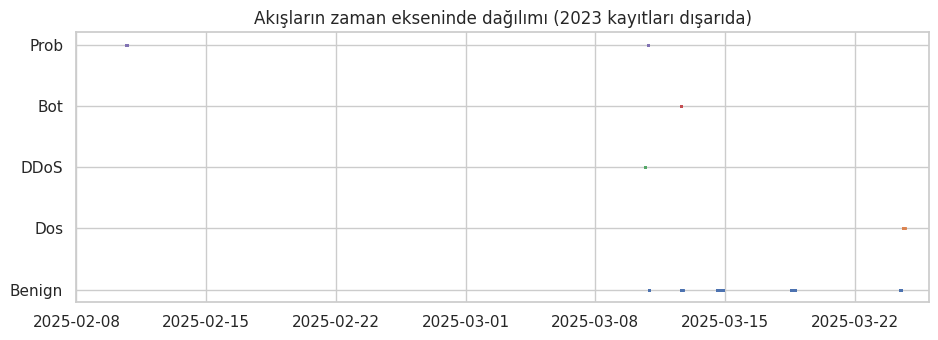

In [11]:
fig, ax = plt.subplots(figsize=(11, 3.5))
for i, lab in enumerate(CLASS_ORDER):
    t = df.loc[df.Label == lab, 'ts']
    ax.scatter(t, np.full(len(t), i), s=1, alpha=.2)
ax.set_yticks(range(5), CLASS_ORDER); ax.set_xlim(pd.Timestamp('2025-02-08'), pd.Timestamp('2025-03-26'))
ax.set_title('Akışların zaman ekseninde dağılımı (2023 kayıtları dışarıda)')
plt.savefig(FIG_DIR + 'eda_timeline.png', dpi=150, bbox_inches='tight'); plt.show()

### 5.0 Aktif dakika ve oturum sayısı
İlk ve son akış arasındaki süre yanıltıcı olabilir: kayıt bu aralığın her dakikasında sürmüyor. Burada her sınıf için **akış olan dakika** sayısını ve **oturum** sayısını sayıyoruz. Oturum = ardışık dakikalar; 1 dakikadan uzun boşluk yeni oturum başlatır. Oturumlar, değerlendirmede kullanılan grupların aynısı (`src/cv.make_groups`).

In [12]:
# 7.7: 'minute' is made with the same function clean() uses; sessions are the CV groups
df = add_eval_columns(df)
df['session'] = make_groups(df)

rows = []
for label in CLASS_ORDER:
    part = df[df['Label'] == label]
    rows.append({'Label': label, 'satır': len(part),
                 'ilk_son_arası_dk': part['minute'].max() - part['minute'].min() + 1,
                 'aktif_dk': part['minute'].nunique(),
                 'oturum': part['session'].nunique()})
display(pd.DataFrame(rows).set_index('Label'))

for label in ['Bot', 'DDoS']:
    part = df[df['Label'] == label]
    print(label, 'oturumları:')
    display(part.groupby('session')['ts'].agg(['min', 'max', 'count']))

,satır,ilk_son_arası_dk,aktif_dk,oturum
Label,,,,
Benign,260797,19620,653,23
Dos,127772,703571,119,23
DDoS,51465,20,11,4
Bot,9090,34,6,3
Prob,7920,40548,32,6


Bot oturumları:


,min,max,count
session,,,
Bot_0,2025-03-12 14:38:51,2025-03-12 14:39:26,1780
Bot_1,2025-03-12 15:07:03,2025-03-12 15:08:54,4665
Bot_2,2025-03-12 15:10:27,2025-03-12 15:11:08,2645


DDoS oturumları:


,min,max,count
session,,,
DDoS_0,2025-03-10 15:47:43,2025-03-10 15:49:43,23960
DDoS_1,2025-03-10 15:55:19,2025-03-10 15:56:36,10611
DDoS_2,2025-03-10 15:59:30,2025-03-10 16:02:03,6889
DDoS_3,2025-03-10 16:05:13,2025-03-10 16:06:20,10005


**Bulgu:**
- Bot **12 Mart 14:38–15:11** aralığında kaydedilmiş, ama bu aralığın sadece **6 dakikasında** akış var: **3 oturum** (14:38–39, 15:07–08, 15:10–11). DDoS **10 Mart 15:47–16:06** aralığında, **11 aktif dakika / 4 oturum**. Yani saldırı sınıfları birkaç kısa oturumdan oluşuyor; değerlendirmede bu oturumlar grup olarak kullanılıyor.
- 20.711 Dos satırı **2023-11-22** tarihli. 5.1'de bu satırların 2025 Dos'tan farklı bir kayıt ortamından geldiği görülüyor (farklı hedef IP, süre ve pencere dağılımları); tarihin doğru olup olmadığını bilmiyoruz. Veri olarak tutuluyor, sınırlılık olarak raporlanıyor.
- `Timestamp` doğrudan kullanılırsa model "saat 14:40 ise Bot" gibi bir kural öğrenebilir. **Timestamp özellik olarak kullanılmıyor** (`clean()` atıyor).
- Rastgele bölmede aynı oturumun komşu akışları hem eğitimde hem testte olur; model saldırı davranışı yerine **o oturuma özgü değerleri** öğrenebilir ve skor yüksek görünür. Bölüm 9'da aynı satırlarda bu fark **0,15–0,21** macro F1 olarak ölçüldü.
- Saf zaman bölmesi (ilk %80 / son %20) da olmaz, çünkü her saldırı sınıfı birkaç kısa oturumdan oluşuyor (Bot 3, DDoS 4). **Çözüm: oturum gruplu çapraz doğrulama** (`src/cv.get_folds`, 3 kat): bir oturumun bütün akışları ya eğitimde ya testte. Her satır bir kez test edilir, sonuç katların ortalaması ± std. Ayrı bir test seti yok.

### 5.1 Dos iki ayrı dönemde kaydedilmiş: 2023 ve 2025
Dos satırlarının bir kısmı 2023-11-22, geri kalanı 2025-03-24 tarihli. Önce iki dönemin sağlam/bozuk dağılımına, sonra **sadece sağlam satırlarda** 4 sütunun dağılımına bakıyoruz (bozuk satırlarda bayt ve pencere sütunları zaten 0 / −1).

broken,False,True,All
year,,,
2023,20703,8,20711
2025,90994,16067,107061
All,111697,16075,127772


year,2023,2025
Flow Duration,1972642.0,8098.0
Flow Pkts/s,2.5,802.9
TotLen Fwd Pkts,2.0,217.0
Init Bwd Win Byts,507.0,85.0


2023 en sık hedef IP: {'192.168.4.17': 17489, '200.175.2.130': 3171}
2025 en sık hedef IP: {'192.168.40.150': 48300, '192.168.20.131': 42478}


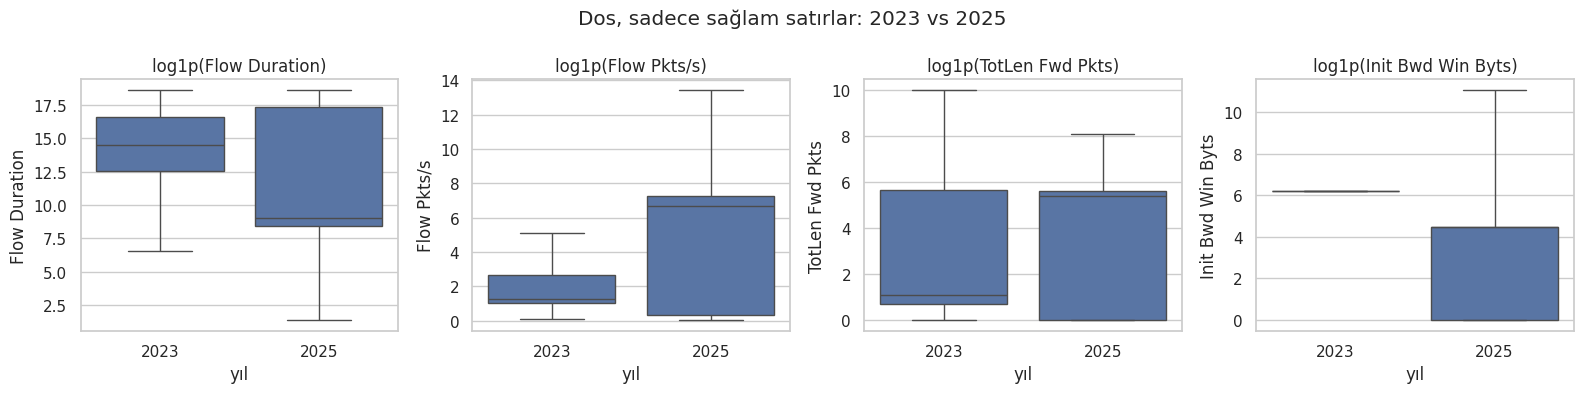

In [13]:
# 7.8: compare the two Dos recording periods
DOS_COMPARE_COLS = ['Flow Duration', 'Flow Pkts/s', 'TotLen Fwd Pkts', 'Init Bwd Win Byts']

dos = df[df['Label'] == 'Dos'].copy()
dos['year'] = dos['ts'].dt.year
display(pd.crosstab(dos['year'], dos['broken'], margins=True))

dos_ok = dos[~dos['broken']]
display(dos_ok.groupby('year')[DOS_COMPARE_COLS].median().T.round(1))

for year in sorted(dos_ok['year'].unique()):
    top_targets = dos_ok.loc[dos_ok['year'] == year, 'Dst IP'].value_counts().head(2)
    print(year, 'en sık hedef IP:', top_targets.to_dict())

fig, axes = plt.subplots(1, len(DOS_COMPARE_COLS), figsize=(16, 4))
for ax, col in zip(axes, DOS_COMPARE_COLS):
    # log1p for readability; clip(0) only for the plot (inf and -1 cannot be drawn on a log axis)
    values = np.log1p(dos_ok[col].replace([np.inf, -np.inf], np.nan).clip(lower=0))
    sns.boxplot(x=dos_ok['year'], y=values, ax=ax, showfliers=False)
    ax.set_title(f'log1p({col})'); ax.set_xlabel('yıl')
plt.suptitle('Dos, sadece sağlam satırlar: 2023 vs 2025')
plt.tight_layout()
plt.savefig(FIG_DIR + 'eda_dos_2023_vs_2025.png', dpi=150, bbox_inches='tight'); plt.show()

**Bulgu (7.8):**
- 2023 Dos'un 20.711 satırının 20.703'ü (%99,96) sağlam, 8'i bozuk. Bozuk Dos satırlarının neredeyse tamamı (16.067) 2025 kaydında.
- Sağlam satırlarda medyanlar (2023 → 2025): süre 1.972.642 → 8.098 µs, Flow Pkts/s 2,5 → 803, TotLen Fwd Pkts 2 → 217 bayt, Init Bwd Win Byts 507 → 85. Grafikte süre, hız ve `Init Bwd Win Byts` dağılımları belirgin şekilde ayrışıyor (2023'te `Init Bwd Win Byts` kutusu tek değerde toplanmış); `TotLen Fwd Pkts`'te medyanlar farklı ama kutular büyük ölçüde örtüşüyor. Hedef IP'ler de farklı (2023: `192.168.4.17`; 2025: `192.168.40.150`, `192.168.20.131`).
- Yani Dos sınıfı **iki ayrı kayıt ortamından** geliyor. Gruplu CV'de bir katın testine 2025'in büyük bir oturumu düşerse, o katın eğitiminde 2025 Dos az kalır ve Dos sonuçları bu kata göre değişebilir. Bunu raporda **sınırlılık** olarak yazıyoruz; etkisi Bölüm 9'daki gruplu CV sonuçlarında ölçülecek.

## 6. Bozuk satırlarda sınıflar zamanlama özellikleriyle ayrışıyor mu?

,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,Flow Pkts/s,Flow IAT Mean,Idle Mean
Label,,,,,,
Benign,64873209.5,1.0,1.0,0.1,21996594.9,25812558.8
Dos,46964482.0,1.0,1.0,0.0,39358024.5,41741425.0
DDoS,26775764.0,1.0,1.0,0.1,23429169.0,24442021.0
Bot,14213919.5,1.0,1.0,0.1,13099496.0,13486968.2
Prob,13670834.5,2.0,1.0,0.4,3822379.5,8196347.0


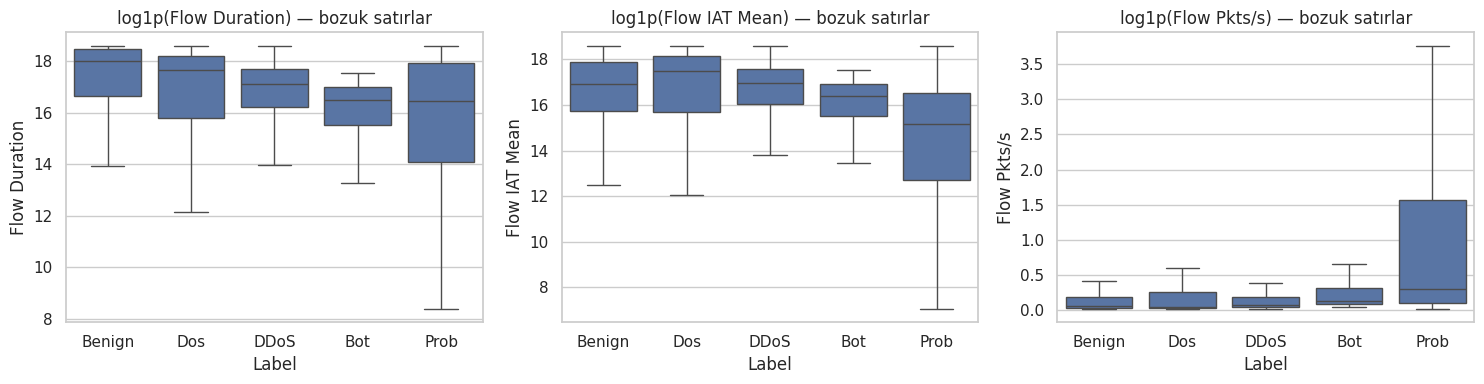

In [14]:
B = df[df.broken]
key = ['Flow Duration', 'Tot Fwd Pkts', 'Tot Bwd Pkts', 'Flow Pkts/s', 'Flow IAT Mean', 'Idle Mean']
display(B.groupby('Label')[key].median().reindex(CLASS_ORDER).round(1))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ['Flow Duration', 'Flow IAT Mean', 'Flow Pkts/s']):
    sns.boxplot(data=B, x='Label', y=np.log1p(B[c].clip(lower=0)), order=CLASS_ORDER, ax=ax, showfliers=False)
    ax.set_title(f'log1p({c}) — bozuk satırlar')
plt.tight_layout(); plt.show()

**Bulgu:** Bozuk satırların çoğu **1 ileri + 1 geri paketlik** ve uzun süreli "akışlar". Sınıflar arasında süre ve IAT farkları var ama dağılımlar büyük ölçüde örtüşüyor. Bot/DDoS/Prob karışıklığının önemli bir nedeninin bu olduğunu düşünüyoruz: **satır başına bilgi az** (8.2: bu satırların çoğunda F_timing vektörü tamamen süreden belirleniyor). Model değiştirmenin bunu ne kadar değiştirdiği sonraki deneylerde ölçülecek.

## 7. Korelasyon (artefaktsız özellikler)

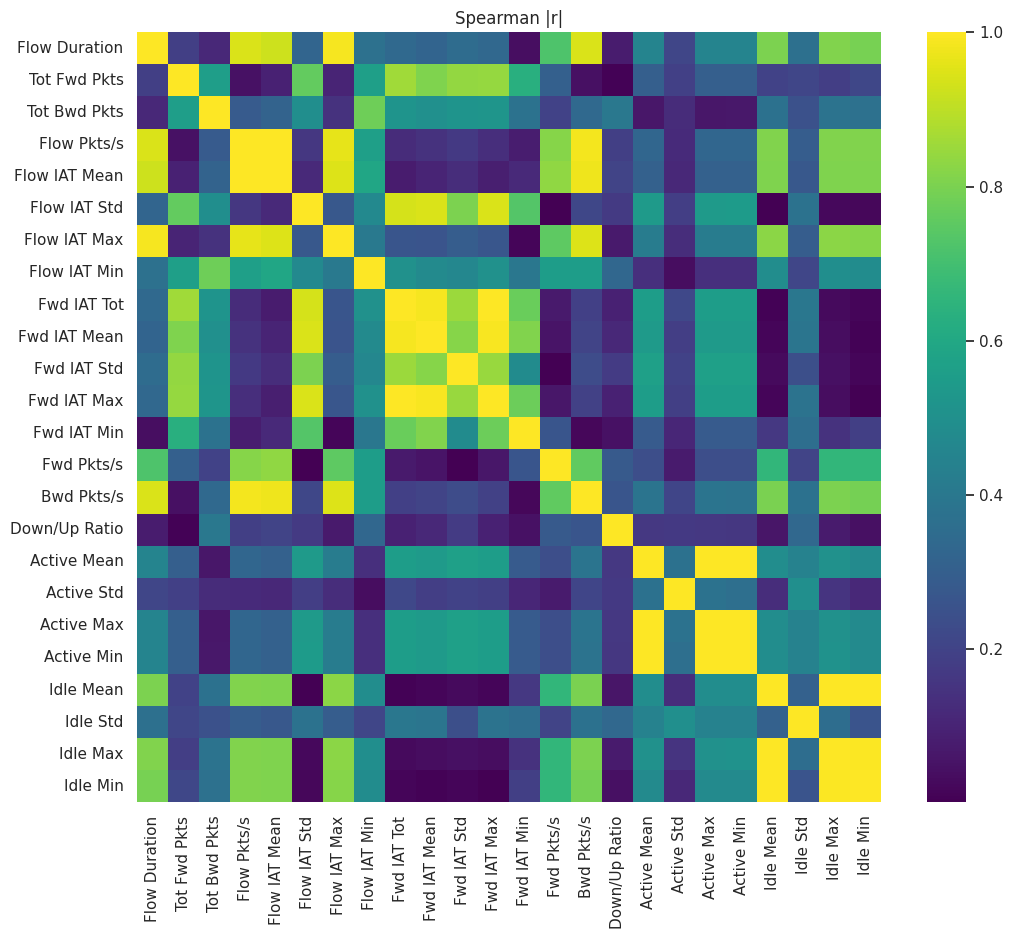

|r| > 0.95 çiftleri:
Active Mean    Active Max       1.000
               Active Min       1.000
Active Max     Active Min       1.000
Idle Mean      Idle Max         0.998
               Idle Min         0.998
Flow Pkts/s    Flow IAT Mean    0.997
Fwd IAT Tot    Fwd IAT Max      0.996
Idle Max       Idle Min         0.993
Fwd IAT Mean   Fwd IAT Max      0.990
Flow Duration  Flow IAT Max     0.986
Fwd IAT Tot    Fwd IAT Mean     0.984
Flow Pkts/s    Bwd Pkts/s       0.982
Flow IAT Mean  Bwd Pkts/s       0.976
Flow Pkts/s    Flow IAT Max     0.963
dtype: float64


In [15]:
corr = df[TIMING_COLS].corr(method='spearman').abs()
plt.figure(figsize=(12, 10)); sns.heatmap(corr, cmap='viridis', xticklabels=True, yticklabels=True); plt.title('Spearman |r|'); plt.show()
upper = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
print('|r| > 0.95 çiftleri:'); print(upper.stack()[lambda s: s > .95].sort_values(ascending=False).round(3))

> F_timing (15) ve F_full (33) listeleri `src/config.py`'de sabit. İlk EDA'da eski eğitim bölmesi üzerinde, |r| > 0,95 olan çiftlerden biri atılarak seçildiler. Burada yeniden hesaplanmıyor; tablo sadece görmek için. İki setin karşılaştırması Bölüm 9'da gruplu CV ile.

## 8. Veri ön işleme: `src/preprocessing.clean()`
Temizleme artık tek bir fonksiyonda (`src/preprocessing.py`). Notebook, deneyler, Streamlit demosu ve Mininet testi aynı fonksiyonu çağırır. `clean()` sırasıyla:
1. `broken` (= `Protocol == 0`) ve `minute` sütunlarını üretir (değerlendirme için; özellik değil)
2. ID / IP / port / Protocol / Timestamp, 14 sabit ve 3 birebir aynı sütunu atar
3. inf/NaN içeren satırları atar (0 ile doldurmaz)
4. Negatif süre/IAT değerlerini 0'a kırpar; `Init Bwd Win Byts` −1 olarak kalır
5. Özellik + etiket tekrarlarını siler; çelişkili satırları silmez (onlar sadece eğitim katından atılır)
6. `label_binary` ekler (Benign = 0, saldırı = 1)

Sütun listeleri (`FEATS`, `F_TIMING`, `F_FULL`...) `src/config.py`'de sabit listedir.

In [16]:
data = clean(df)
assert list(data.columns) == FEATS + ['Label', 'label_binary', 'broken', 'minute']
print('ham satır:', len(df), '-> clean():', data.shape)
display(pd.crosstab(data['Label'], data['broken'], margins=True).reindex(CLASS_ORDER + ['All']))

clean: dropped 70 rows with inf/NaN
clean: clipped negative values to 0 in 427 rows


clean: removed 29930 duplicate rows (features + label)
clean: final shape (427044, 63)
ham satır: 457044 -> clean(): (427044, 63)


broken,False,True,All
Label,,,
Benign,191810,41937,233747
Dos,110813,15693,126506
DDoS,0,50269,50269
Bot,0,8957,8957
Prob,0,7565,7565
All,302623,124421,427044


### 8.1 Dengesizlik oranı ve IQR outlier oranı (temiz veri)
Dengesizlik oranı = en büyük sınıf / en küçük sınıf. Outlier: sınıfın kendi içinde, bir özellik değeri Q1 − 1,5·IQR altında ya da Q3 + 1,5·IQR üstündeyse. Tabloda, en az bir özelliği outlier olan satırların yüzdesi var.

In [17]:
IQR_FACTOR = 1.5   # standard Tukey rule

counts = data['Label'].value_counts()
print(f'Dengesizlik oranı: {counts.idxmax()} / {counts.idxmin()} = {counts.max() / counts.min():.1f} : 1')


def outlier_row_pct(frame, cols):
    """Returns the % of rows that have at least one IQR outlier in cols.
    Quartiles are computed inside the given frame (one class at a time)."""
    q1 = frame[cols].quantile(0.25)
    q3 = frame[cols].quantile(0.75)
    iqr = q3 - q1
    is_outlier = (frame[cols] < q1 - IQR_FACTOR * iqr) | (frame[cols] > q3 + IQR_FACTOR * iqr)
    return is_outlier.any(axis=1).mean() * 100


rows = []
for label in CLASS_ORDER:
    part = data[data['Label'] == label]
    rows.append({'Label': label, 'satır': len(part),
                 'outlier_satır_%_FEATS': round(outlier_row_pct(part, FEATS), 1),
                 'outlier_satır_%_F_TIMING': round(outlier_row_pct(part, F_TIMING), 1),
                 'IQR=0_sütun_(FEATS)': int((part[FEATS].quantile(0.75) == part[FEATS].quantile(0.25)).sum())})
display(pd.DataFrame(rows).set_index('Label'))

Dengesizlik oranı: Benign / Prob = 30.9 : 1


,satır,outlier_satır_%_FEATS,outlier_satır_%_F_TIMING,IQR=0_sütun_(FEATS)
Label,,,,
Benign,233747,90.1,59.9,14
Dos,126506,79.2,47.7,7
DDoS,50269,28.3,27.4,49
Bot,8957,22.4,22.4,49
Prob,7565,77.3,75.7,38


**Bulgu (7.10):** Temiz veride dengesizlik **30,9 : 1** (Benign / Prob; ham veride 32,9 : 1). IQR kuralı, sınıfa göre satırların %22–%90'ını "outlier" sayıyor (FEATS ile). DDoS ve Bot'ta 59 sütunun 49'unun IQR'ı 0; bu sütunlarda sıfır olmayan her değer outlier görünüyor. Bu kadar geniş bir kural veriden gerçek akışları da atar ve sınıf dengesini değiştirir. Bu yüzden **outlier satırları silinmiyor**. Kullandığımız ağaç tabanlı modeller ölçeklemeden etkilenmez ve uç değerlere görece dayanıklıdır.

### 8.2 Bozuk + 1/1 paketli satırlarda F_timing tamamen süreye mi bağlı?
Bozuk satırların çoğu 1 ileri + 1 geri paketlik. Bu satırlarda IAT, hız, aktif/boşta süreleri tek bir sayıdan, akış süresinden türetiliyor olabilir. Kontrol: satır sayısı, farklı `Flow Duration` sayısı ve farklı F_timing vektörü sayısı. Farklı süre sayısı = farklı vektör sayısı ise, vektörün tamamı süreden belirleniyor demektir.

In [18]:
one_one = data['broken'] & (data['Tot Fwd Pkts'] == 1) & (data['Tot Bwd Pkts'] == 1)
sub = data[one_one]


def count_unique(frame):
    """Returns rows, distinct durations and distinct F_TIMING vectors of a frame."""
    return {'satır': len(frame),
            'farklı_süre': frame['Flow Duration'].nunique(),
            'farklı_F_TIMING_vektörü': len(frame[F_TIMING].drop_duplicates())}


# The second row removes conflicting rows (same F_TIMING, different label) only to reproduce the
# number in the comparison report; clean() keeps them (they are dropped only from training folds).
has_conflict = sub.groupby(F_TIMING)['Label'].transform('nunique') > 1
table = pd.DataFrame([count_unique(sub), count_unique(sub[~has_conflict])],
                     index=['clean() verisi', 'çelişkili satırlar atılınca'])
display(table)

share_rows = []
for label in CLASS_ORDER:
    n_class = (data['Label'] == label).sum()
    n_sub = (sub['Label'] == label).sum()
    share_rows.append({'Label': label, 'bozuk_1/1_satır': n_sub, 'sınıf_içindeki_payı_%': round(n_sub / n_class * 100, 1)})
display(pd.DataFrame(share_rows).set_index('Label'))

,satır,farklı_süre,farklı_F_TIMING_vektörü
clean() verisi,95994,95105,95105
çelişkili satırlar atılınca,94438,94438,94438


,bozuk_1/1_satır,sınıf_içindeki_payı_%
Label,,
Benign,27342,11.7
Dos,14567,11.5
DDoS,42992,85.5
Bot,8254,92.2
Prob,2839,37.5


**Bulgu (7.6):**
- `clean()` verisinde bozuk + 1/1 paketli 95.994 satır var; bunlarda farklı süre sayısı (95.105) = farklı F_timing vektörü sayısı (95.105). Yani bu satırlarda F_timing vektörünün tamamı **akış süresinden** belirleniyor.
- Aradaki 889 fark tekrar değil: aynı süreye sahip ama farklı etiket taşıyan satırlar. Çelişkili satırlar atılınca karşılaştırma raporundaki sayı çıkıyor: 94.438 / 94.438 / 94.438.
- Bu satırlar Bot'un %92,2'si, DDoS'un %85,5'i. Bu iki sınıf arasında, bu satırlarda ayrım için elde kalan bilgi süre.

### 8.3 Mutual information: hangi özellik etiket hakkında bilgi taşıyor?
`mutual_info_classif` ile, tüm veride ve sadece bozuk satırlarda, 59 özelliğin etiketle ortak bilgisi. Hız için sınıflara göre tabakalı (stratified) 50.000 satırlık örnek kullanılıyor. İlk 15 özellik gösteriliyor.

,tüm veri,MI (tüm),bozuk alt küme,MI (bozuk)
1,Fwd Header Len,0.597,Flow Duration,0.296
2,Bwd Header Len,0.596,Bwd Pkts/s,0.294
3,Pkt Len Max,0.510,Flow IAT Min,0.273
4,Pkt Len Var,0.504,Flow IAT Max,0.230
5,Pkt Size Avg,0.504,Idle Min,0.224
6,Pkt Len Std,0.502,Flow IAT Mean,0.222
7,Pkt Len Mean,0.500,Fwd Pkts/s,0.221
8,Init Bwd Win Byts,0.479,Flow Pkts/s,0.207
9,Bwd Pkts/s,0.478,Idle Max,0.194
10,Flow IAT Mean,0.462,Idle Mean,0.182


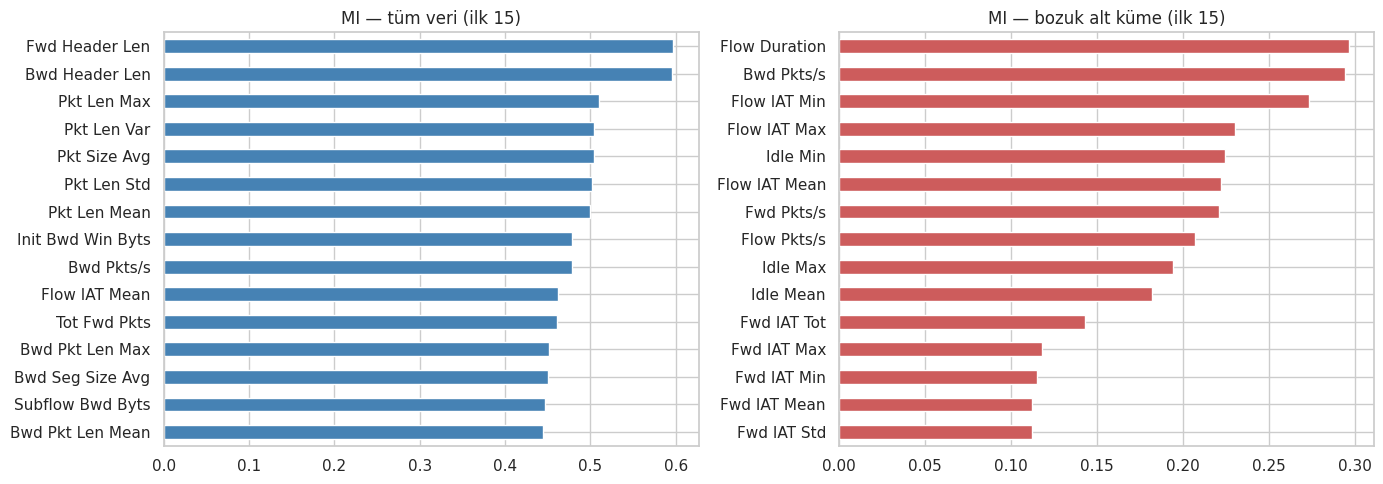

In [19]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split

MI_SAMPLE_SIZE = 50_000
MI_TOP_N = 15


def mi_top(frame, n_rows, top_n):
    """Stratified sample of n_rows, mutual information of FEATS with Label.
    Returns the top_n features as a Series (largest first)."""
    sample, _ = train_test_split(frame, train_size=n_rows, stratify=frame['Label'], random_state=RANDOM_STATE)
    scores = mutual_info_classif(sample[FEATS], sample['Label'], random_state=RANDOM_STATE)
    scores = pd.Series(scores, index=FEATS).sort_values(ascending=False)
    return scores.head(top_n).round(3)


mi_all = mi_top(data, MI_SAMPLE_SIZE, MI_TOP_N)
mi_broken = mi_top(data[data['broken']], MI_SAMPLE_SIZE, MI_TOP_N)
display(pd.DataFrame({'tüm veri': mi_all.index, 'MI (tüm)': mi_all.values,
                      'bozuk alt küme': mi_broken.index, 'MI (bozuk)': mi_broken.values},
                     index=range(1, MI_TOP_N + 1)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
mi_all[::-1].plot.barh(ax=axes[0], color='steelblue'); axes[0].set_title('MI — tüm veri (ilk 15)')
mi_broken[::-1].plot.barh(ax=axes[1], color='indianred'); axes[1].set_title('MI — bozuk alt küme (ilk 15)')
plt.tight_layout()
plt.savefig(FIG_DIR + 'eda_mutual_info.png', dpi=150, bbox_inches='tight'); plt.show()

**Bulgu (7.11):**
- Tüm veride ilk sıralar başlık uzunluğu ve paket boyu sütunları (`Fwd/Bwd Header Len` ≈ 0,60, `Pkt Len *` ≈ 0,50). Bunlar bozuk satırlarda hep 0 olan artefakt sütunları; yüksek MI'larının bir kısmı "bozuk mu?" bilgisinden geliyor olabilir.
- Bozuk alt kümede ilk 15 özelliğin hepsi süre, hız, IAT ve boşta (idle) sütunları; en yüksek `Flow Duration` (0,296). Bozuk satırlarda etiketle ilgili bilgi zamanlama sütunlarında toplanıyor; bu da 8.2'deki "vektör süreden belirleniyor" bulgusuyla uyumlu.
- MI tek tek sütunlara bakar, sütunların birlikte taşıdığı bilgiyi göstermez; 50.000 satırlık örnekle hesaplandı.

**Neden iki set?**
- **F_timing** (ana deney): sadece zamanlama ve paket sayısı sütunları; bayt, başlık ve flag sütunları yok. Byte kısayolu kalktı, ama bozuk-oturum bilgisi zamanlamada duruyor (8.4, AUC 0,998). Bu sütunların Mininet'te de aynı anlamda ölçüleceğini varsayıyoruz; bu doğrulanmadı.
- **F_full**: Literatürle kıyas için. Raporda "artefakt özellikleri çıkarınca ne kaybettik" sorusunu cevaplar.

### 8.4 F_timing bozuk satırları ele veriyor mu?
Byte / header / flag sütunlarını çıkardık. Ama bozuk satırlar zamanlama sütunlarında da farklıysa, model "bozuk oturum" bilgisini yine öğrenebilir. Kontrol: sadece F_timing ile `broken` bayrağını tahmin eden bir model. Gruplu katlar (`get_folds`), her satır bir kez test edilir (out-of-fold), skor ROC AUC (0,5 = ayıramıyor, 1,0 = tamamen ayırıyor).

Not: Burada hedef `Label` değil `broken`; bu bir model sonucu değil, sızıntı kontrolü. Bu yüzden `run_cv` yerine katlar `get_folds` ile alınıp AUC burada hesaplanıyor (plan 7.4: HistGradientBoosting).

In [20]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

folds = get_folds(data)
is_broken = data['broken'].astype(int).to_numpy()
oof_proba = np.zeros(len(data))

for fold_no, (train_idx, test_idx) in enumerate(folds):
    model = HistGradientBoostingClassifier(random_state=RANDOM_STATE)
    model.fit(data[F_TIMING].iloc[train_idx], is_broken[train_idx])
    oof_proba[test_idx] = model.predict_proba(data[F_TIMING].iloc[test_idx])[:, 1]
    print(f'kat {fold_no}: AUC = {roc_auc_score(is_broken[test_idx], oof_proba[test_idx]):.4f}')

print(f'\nOOF AUC, tüm veri: {roc_auc_score(is_broken, oof_proba):.4f}')
# Benign and Dos have both broken and healthy rows: AUC inside one class cannot come from the label
for label in ['Benign', 'Dos']:
    in_class = (data['Label'] == label).to_numpy()
    print(f'OOF AUC, sadece {label}: {roc_auc_score(is_broken[in_class], oof_proba[in_class]):.4f}')

kat 0: AUC = 0.9957


kat 1: AUC = 0.9989


kat 2: AUC = 0.9987

OOF AUC, tüm veri: 0.9979
OOF AUC, sadece Benign: 0.9985
OOF AUC, sadece Dos: 0.9969


### 8.5 Sağlam ve bozuk satırlar zamanlama olarak da farklı mı?
8.4'teki AUC'nin nedenini görmek için: Benign ve Dos'ta (iki türde de satırı olan sınıflar) sağlam / bozuk satırların medyanları.

In [21]:
MEDIAN_COLS = ['Flow Duration', 'Tot Fwd Pkts', 'Tot Bwd Pkts', 'Flow Pkts/s']

benign_dos = data[data['Label'].isin(['Benign', 'Dos'])]
medians = benign_dos.groupby(['Label', 'broken'])[MEDIAN_COLS].median()
display(medians.round(1))

Flow Duration  Tot Fwd Pkts  Tot Bwd Pkts  Flow Pkts/s
Label  broken                                                        
Benign False         95887.5           7.0           5.0        174.6
       True       66894382.0           1.0           1.0          0.1
Dos    False        182591.0           2.0           5.0         21.5
       True       50556625.0           1.0           1.0          0.0

**Bulgu (7.4 + 7.5):**
- Sadece F_timing ile `broken` bayrağı gruplu CV'de **OOF AUC = 0,998** ile tahmin ediliyor (katlar 0,996 / 0,999 / 0,999). Sınıf içinde de aynı: sadece Benign 0,998, sadece Dos 0,997; yani bu ayrım etiketten gelmiyor.
- Nedeni 8.5'teki tablo: bozuk satırlar medyanda 1 ileri + 1 geri paketlik ve çok uzun (Benign 66,9 sn, Dos 50,6 sn); sağlam satırlar 0,1–0,2 sn ve daha çok paketli. Hız da buna göre çok düşük (≈ 0,1 paket/sn).
- Sonuç: **byte kısayolu kalktı, ama bozuk-oturum bilgisi zamanlama sütunlarında da duruyor.** F_timing ile eğitilen bir model bu bilgiyi kullanabilir; bunu raporda sınırlılık olarak yazıyoruz.
- Not: Karşılaştırma raporundaki değer 0,9997; o değer eski temizlik ve eski bölmeyle hesaplanmıştı. Buradaki değer `clean()` + `get_folds()` ile.

## 9. Sızıntı kontrolü: rastgele CV vs. oturum gruplu CV
Aynı satırlar (`clean()` verisi), aynı model (`LGBMClassifier`, varsayılan parametreler), iki farklı kat bölmesi:
- **rastgele** (`get_random_folds`): sınıf oranlı 3 kat, oturumlara bakmaz. Aynı oturumun akışları hem eğitimde hem testte olabilir.
- **gruplu** (`get_folds`): oturum gruplu 3 kat. Bir oturum ya eğitimde ya testte.

Her iki özellik seti (F_full, F_timing) için. Skorlar `run_cv` ile: kat başına macro F1 (ortalama ± std), sağlam ve bozuk alt kümede macro F1, sınıf recall'ları. Ayrı test seti yok; her satır bir kez test edilir. F_full / F_timing seçimi de buradaki gruplu sonuçlara göre yapılır.

In [22]:
import os
from lightgbm import LGBMClassifier
from imblearn.pipeline import Pipeline
from src.cv import get_random_folds, print_fold_table, run_cv

# Temporary results file for this notebook only (data/ is git-ignored, not committed).
EDA_CV_CSV = '../data/processed/eda_cv.csv'
if os.path.exists(EDA_CV_CSV):
    os.remove(EDA_CV_CSV)   # run_cv appends rows; start fresh so a re-run does not duplicate them

grouped_folds = get_folds(data)
random_folds = get_random_folds(data)
print('Gruplu katlar:')
grouped_table = print_fold_table(data, grouped_folds)

Gruplu katlar:
Test kısmındaki satır sayıları (sınıf × kat):
        fold_0  fold_1  fold_2
Label                         
Benign   76910   79965   76872
Bot       1757    2585    4615
DDoS     23953   10599   15717
Dos      16482   16711   93313
Prob      2803    2316    2446
Test kısmındaki oturum sayıları (sınıf × kat):
        fold_0  fold_1  fold_2
Label                         
Benign       9       3      11
Bot          1       1       1
DDoS         1       1       2
Dos         19       3       1
Prob         1       1       4


4 çalıştırma: {F_full, F_timing} × {rastgele, gruplu}. Her çalıştırma `EDA_CV_CSV`'ye bir satır ekler.

In [23]:
pipe = Pipeline([('model', LGBMClassifier(random_state=RANDOM_STATE, verbose=-1))])

results = []
confusions = {}
oofs = {}
for feats, set_name in [(F_FULL, 'F_full'), (F_TIMING, 'F_timing')]:
    for folds, cv_name in [(random_folds, 'random'), (grouped_folds, 'grouped')]:
        print(f'\n=== {set_name} | {cv_name} ===')
        row, cm, oof = run_cv(pipe, data, feats, EDA_CV_CSV, experiment='EDA-9', sampler='none',
                              feature_set=set_name, folds=folds, note='WP-D1 7.2')
        results.append(row)
        confusions[(set_name, cv_name)] = cm
        oofs[(set_name, cv_name)] = oof

SHOW_COLS = ['feature_set', 'cv', 'macro_f1_mean', 'macro_f1_std', 'macro_f1_clean', 'macro_f1_broken',
             'recall_Benign', 'recall_Dos', 'recall_DDoS', 'recall_Bot', 'recall_Prob', 'bot_ddos_confusion']
display(pd.DataFrame(results)[SHOW_COLS].round(3))


=== F_full | random ===
Kat 0


  eğitim: 283836 satır (çelişki atılan: 860 ) | test: 142348 | fit: 3.7 sn
Kat 1


  eğitim: 283909 satır (çelişki atılan: 787 ) | test: 142348 | fit: 3.5 sn


Kat 2


  eğitim: 283865 satır (çelişki atılan: 831 ) | test: 142348 | fit: 3.5 sn


Kat F1'leri: [0.6452 0.6466 0.6456] → 0.6458 ± 0.0007
CSV'ye eklendi: ../data/processed/eda_cv.csv


... (13 outputs left out)

  eğitim: 309862 satır (çelişki atılan: 5006 ) | test: 112176 | fit: 2.3 sn
Kat 2


  eğitim: 230078 satır (çelişki atılan: 4003 ) | test: 192963 | fit: 2.2 sn


Kat F1'leri: [0.4262 0.5334 0.2952] → 0.4183 ± 0.1193
CSV'ye eklendi: ../data/processed/eda_cv.csv


,feature_set,cv,macro_f1_mean,macro_f1_std,macro_f1_clean,macro_f1_broken,recall_Benign,recall_Dos,recall_DDoS,recall_Bot,recall_Prob,bot_ddos_confusion
0,F_full,random,0.646,0.001,0.999,0.457,0.922,0.905,0.833,0.057,0.467,0.136
1,F_full,grouped,0.499,0.052,0.837,0.339,0.913,0.560,0.718,0.033,0.329,0.145
2,F_timing,random,0.630,0.005,0.989,0.432,0.923,0.877,0.821,0.046,0.438,0.133
3,F_timing,grouped,0.418,0.119,0.512,0.324,0.911,0.119,0.713,0.031,0.275,0.140


Gruplu CV, kat bazında: her katın test kısmında macro F1, sağlam alt küme F1'i ve Dos recall'u. Metrikler `run_cv`'nin döndürdüğü OOF tahminlerinden, `src/cv.compute_metrics` ile hesaplanıyor (yeni ölçüm kodu yok). Son iki sütun: o katın **eğitim** kısmındaki Dos satırlarının kaç tanesi 2023, kaç tanesi 2025 kaydından.

In [24]:
from src.cv import compute_metrics

YEAR_2024_START_MINUTE = pd.Timestamp('2024-01-01').timestamp() / 60   # 'minute' = minutes since 1970
labels = data['Label'].to_numpy()
broken = data['broken'].to_numpy()
is_dos_2023 = ((data['Label'] == 'Dos') & (data['minute'] < YEAR_2024_START_MINUTE)).to_numpy()
is_dos_2025 = ((data['Label'] == 'Dos') & (data['minute'] >= YEAR_2024_START_MINUTE)).to_numpy()

fold_rows = []
for set_name in ['F_full', 'F_timing']:
    oof = oofs[(set_name, 'grouped')].to_numpy()
    for fold_no, (train_idx, test_idx) in enumerate(grouped_folds):
        m = compute_metrics(labels[test_idx], oof[test_idx], broken[test_idx])
        fold_rows.append({'set': set_name, 'kat': fold_no,
                          'macro_f1': round(m['macro_f1'], 3), 'sağlam_f1': round(m['macro_f1_clean'], 3),
                          'recall_Dos': round(m['recall_Dos'], 3),
                          'test_Dos_satır': int((labels[test_idx] == 'Dos').sum()),
                          'eğitim_Dos_2023': int(is_dos_2023[train_idx].sum()),
                          'eğitim_Dos_2025': int(is_dos_2025[train_idx].sum())})
display(pd.DataFrame(fold_rows).set_index(['set', 'kat']))

macro_f1  sağlam_f1  recall_Dos  test_Dos_satır  \
set      kat                                                    
F_full   0       0.455      0.552       0.127           16482   
         1       0.556      0.995       0.853           16711   
         2       0.485      0.814       0.583           93313   
F_timing 0       0.426      0.565       0.135           16482   
         1       0.533      0.955       0.733           16711   
         2       0.295      0.316       0.006           93313   

              eğitim_Dos_2023  eğitim_Dos_2025  
set      kat                                    
F_full   0              14131            95893  
         1               6413           103382  
         2              20544            12649  
F_timing 0              14131            95893  
         1               6413           103382  
         2              20544            12649

Confusion matrix: F_timing, gruplu CV (satır bazında normalize; satır = gerçek sınıf).

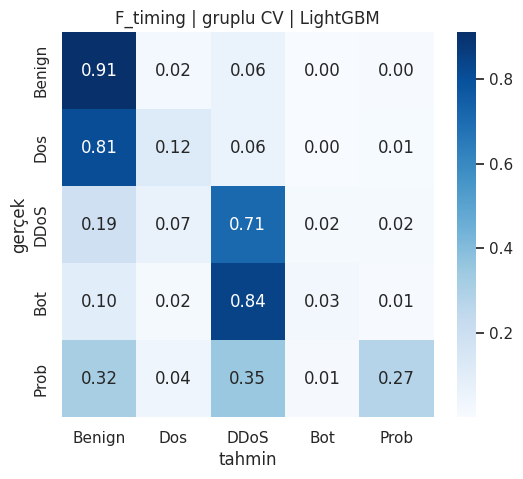

In [25]:
cm = confusions[('F_timing', 'grouped')]
cm_normalized = cm.div(cm.sum(axis=1), axis=0)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues')
plt.title('F_timing | gruplu CV | LightGBM'); plt.ylabel('gerçek'); plt.xlabel('tahmin')
plt.savefig(FIG_DIR + 'eda_cm_ftiming_grouped.png', dpi=150, bbox_inches='tight'); plt.show()

**Bulgu (7.2):**
- **Rastgele CV skoru şişiriyor:** aynı satırlarda rastgele katlar macro F1'i gruplu katlardan **0,15–0,21** yüksek gösteriyor (F_full 0,646 → 0,499; F_timing 0,630 → 0,418). Rastgele katların std'si çok küçük (≤ 0,005), gruplu katlarınki büyük (0,052 / 0,119): gruplu sonuç, hangi oturumun testte olduğuna bağlı.
- **F_full ile F_timing (gruplu):** F_full **0,08** daha yüksek (0,499 ± 0,052'ye karşı 0,418 ± 0,119). Farkın çoğu sağlam alt kümeden: sağlam F1 0,837'ye karşı 0,512, Dos recall 0,56'ya karşı 0,12. Bozuk alt kümede fark küçük (0,339'a karşı 0,324). Bu, bayt / başlık sütunlarını çıkarmanın bedeli olarak raporlanır.
- **Karar:** Ana deney seti **F_timing**, karşılaştırma seti **F_full**. Gerekçe: deney tutarlılığı (WP-B1 / WP-B2 deneyleri F_TIMING ile) ve Mininet'e taşınabilirlik (bayt sütunlarının Mininet'te farklı ölçülme riski). 8.4'te gösterildiği gibi F_timing de `broken` bilgisini taşıyor; bu seçim o sınırlılığı ortadan kaldırmıyor.
- **Kötü kat (F_timing, kat 2, macro F1 0,295):** Dos'un 2025 kaydında 93.313 satırlık tek bir oturum var ve `get_folds` oturumları bölmediği için bu oturum tek başına kat 2'nin testine düşüyor. O katta eğitimdeki Dos satırlarının %62'si 2023 kaydından (20.544'e karşı 12.649); diğer katlarda bu oran %6–13. Yani kat 2 fiilen bir **"kayıt ortamları arası genelleme" testi** oluyor ve F_timing ile Dos'un çoğu Benign tahmin ediliyor. Bu, 5.1'deki iki kayıt ortamı bulgusuyla **tutarlı, ama nedensellik doğrulanmadı.** Kat 2'de Dos recall'u F_timing ile 0,006, F_full ile 0,583. Ayrıca kat 0'da da Dos recall'u düşük (0,13–0,14), oysa o katın eğitimindeki Dos'un %87'si 2025 kaydından; yani düşük Dos recall'u yalnızca kayıt ortamıyla açıklanamıyor.
- **Bot:** Bot recall'u dört çalıştırmanın hepsinde 0,03–0,06. F_timing gruplu CV'de Bot satırlarının **%84'ü DDoS** tahmin ediliyor. Bu, 8.2'deki bulguyla (Bot ve DDoS satırlarının çoğunda bilgi sadece süre) uyumlu; Bot/DDoS ayrımı WP-D2'de ayrıca incelenecek.

## Diğer notebook'lara devredilen kurallar
- Veri her zaman `clean(pd.read_csv(DATA_PATH))` ile hazırlanır; sütun listeleri (`FEATS`, `F_TIMING`, `F_FULL` …) sadece `src/config.py`'den alınır.
- Değerlendirme: `src/cv.get_folds()` ile oturum gruplu 3 kat. Sonuç her zaman ortalama ± std. Ayrı test seti yok, hiperparametre araması yok.
- Her sonuç `run_cv()` ile kaydedilir ve üç skorla raporlanır: tüm veri, sağlam alt küme (Benign/Dos), bozuk alt küme (5 sınıf).
- Sampler / scaler sadece eğitim katında fit edilir (`imblearn.pipeline.Pipeline` içinde). Çelişkili satırlar sadece eğitim katından atılır (`run_cv` bunu yapar).
- Deney modeli: `LGBMClassifier(random_state=42, verbose=-1)`, varsayılan parametreler.
- Mininet testinde F_timing sütunları üretilir. Bozuk-oturum bilgisinin zamanlamada da bulunması (8.4) ve Dos'taki iki kayıt ortamı (5.1) dağılım kayması riski olarak not edilir.